In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## loss-landscape

**Figure 5: Training-loss landscape of ResNet-56 (5.89% test error) on CIFAR-10 around its trained minimizer, redrawn from Li et al. (2018), Figure 5(b).** Contour lines show f(α, β) = L(θ* + αδ + βη) along two filter-normalized random directions δ (Direction 1) and η (Direction 2), labelled with the loss; the minimizer θ* is at the origin. With skip connections, the minimizer sits in a wide, nearly convex basin whose contours stay roughly elliptical up to a loss of about 2.1, about 0.5 from the minimizer in each direction.

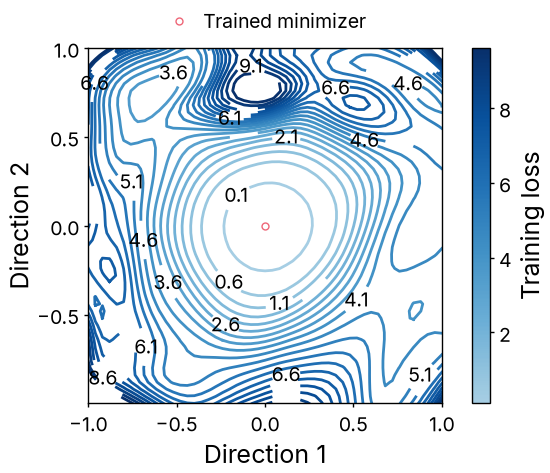

In [2]:
from matplotlib import rcParams
from matplotlib.colors import ListedColormap, Normalize

data = json.load(open("../data/loss-landscape.json"))
cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.35, 1, 256)))
norm = Normalize(min(data["levels"]), max(data["levels"]))

fig, ax = plt.subplots(figsize=(2.75, 2.75))
for line in data["contour_lines"]:
    x, y = np.array(line["xy"]).T
    ax.plot(x, y, color=cmap(norm(line["level"])), linewidth=rcParams["contour.linewidth"])
# at this print size some of the paper's labels would overlap; keep the first of each crowded group
placed = []
for label in data["level_labels"]:
    x, y = label["xy"]
    if all(abs(x - px) > 0.25 or abs(y - py) > 0.16 for px, py in placed):
        ax.text(x, y, f"{label['level']:.2g}", ha="center", va="center")
        placed.append((x, y))
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="Training loss")
ax.plot(0, 0, "o", color=colors["ours"], label="Trained minimizer")
ax.set_xlim(data["x_range"])
ax.set_ylim(data["y_range"])
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_xlabel("Direction 1")
ax.set_ylabel("Direction 2")
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, frameon=False)
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/loss-landscape.pdf")
fig.savefig("../outputs/loss-landscape.png")
plt.show()